In [132]:
%cd /content

!if [ -d "CMPE_258_TrafficForecastingUsing_GraphNN/.git" ]; then \
    git -C CMPE_258_TrafficForecastingUsing_GraphNN pull origin megha-work; \
else \
    git clone -b megha-work https://github.com/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN.git; \
fi

%cd /content/CMPE_258_TrafficForecastingUsing_GraphNN

/content
From https://github.com/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN
 * branch            megha-work -> FETCH_HEAD
Already up to date.
/content/CMPE_258_TrafficForecastingUsing_GraphNN


In [133]:
pwd


'/content/CMPE_258_TrafficForecastingUsing_GraphNN'

In [134]:
!pip install -r requirements.txt -q

In [135]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [136]:
!mkdir -p data/raw data/processed

In [137]:
!cp -r "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/." data/raw/
!cp -r "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/processed/." data/processed/

In [138]:
!ls -lh data/raw
!ls -lh data/processed

total 1.2M
-rw------- 1 root root  286 Nov 14 05:39 adj_correlation_metadata.json
-rw------- 1 root root 168K Nov 14 05:39 adj_correlation.npy
-rw------- 1 root root  306 Nov 14 05:39 adj_distance_metadata.json
-rw------- 1 root root 168K Nov 14 05:39 adj_distance.npy
-rw------- 1 root root 665K Nov 14 05:39 adj_mx.pkl
-rw------- 1 root root 104K Nov 14 05:39 correlation_graph_heatmap.png
-rw------- 1 root root  86K Nov 14 05:39 distance_graph_heatmap.png
-rw------- 1 root root  240 Nov 14 05:39 graph_comparison_metadata.json
total 32M
-rw------- 1 root root  898 Nov 14 05:39 meta.json
-rw------- 1 root root  32M Nov 14 05:39 metr_la_processed.npz
-rw------- 1 root root 7.9K Nov 14 05:39 scalers.json


In [139]:
import numpy as np
import os

processed = np.load(
    "data/processed/metr_la_processed.npz"
)

correlation_graph = np.load(
    "data/raw/adj_correlation.npy"
)

print("Processed data:", processed.files)
print("Correlation graph shape:", correlation_graph.shape)
print(
    "Correlation graph nonzero values:",
    (correlation_graph > 0).sum()
)

Processed data: ['speeds', 'inputs', 'observed', 'timestamps', 'sensor_ids', 'adj_distance']
Correlation graph shape: (207, 207)
Correlation graph nonzero values: 2926


In [140]:
import random
import numpy as np
import torch

SEED = 2024

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Using seed:", SEED)

Using seed: 2024


In [141]:
GRAPH_NAME = "correlation"

RESULTS_DIR = f"results/dcrnn_{GRAPH_NAME}_seed{SEED}"
CHECKPOINT_PATH = f"{RESULTS_DIR}/best_model.pt"

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

print(RESULTS_DIR)

results/dcrnn_correlation_seed2024


In [142]:
import json

print("Inputs shape:", processed["inputs"].shape)
print("Speeds shape:", processed["speeds"].shape)
print("Observed shape:", processed["observed"].shape)

with open("data/processed/meta.json") as f:
    meta = json.load(f)

print("Metadata:")
print(meta)

Inputs shape: (34272, 207)
Speeds shape: (34272, 207)
Observed shape: (34272, 207)
Metadata:
{'shape': {'timesteps': 34272, 'sensors': 207}, 'time_range': ['2012-03-01 00:00:00', '2012-06-27 23:55:00'], 'split_index': {'train': [0, 23990], 'val': [23990, 27417], 'test': [27417, 34272]}, 'split_time': {'train': ['2012-03-01 00:00:00', '2012-05-23 07:05:00'], 'val': ['2012-05-23 07:10:00', '2012-06-04 04:40:00'], 'test': ['2012-06-04 04:45:00', '2012-06-27 23:55:00']}, 'missing_pct_overall': 8.109350825676486, 'missing_pct_by_split': {'train': 7.132198802641197, 'val': 6.962188587643733, 'test': 12.102523987216214}, 'fully_missing_steps': 2148, 'input_imputation': 'ffill', 'windows': {'input_len': 12, 'horizons': [3, 6, 12], 'output_len': 12}}


In [143]:
import numpy as np

print("Inputs:")
print("Minimum:", np.nanmin(processed["inputs"]))
print("Maximum:", np.nanmax(processed["inputs"]))
print("Mean:", np.nanmean(processed["inputs"]))

print("\nSpeeds:")
print("Minimum:", np.nanmin(processed["speeds"]))
print("Maximum:", np.nanmax(processed["speeds"]))
print("Mean:", np.nanmean(processed["speeds"]))

Inputs:
Minimum: -30.952944
Maximum: 6.9350677
Mean: -0.017489977

Speeds:
Minimum: 0.0
Maximum: 70.0
Mean: 53.71902


In [144]:
with open("data/processed/scalers.json") as f:
    scalers = json.load(f)

print(type(scalers))

if isinstance(scalers, dict):
    print(scalers.keys())
    for key, value in scalers.items():
        print(key, type(value))
        print(str(value)[:300])

<class 'dict'>
dict_keys(['mean', 'std'])
mean <class 'list'>
[61.91374969482422, 64.42971801757812, 64.68721008300781, 52.96262741088867, 49.83348846435547, 55.02029037475586, 58.47807693481445, 63.20731735229492, 60.708221435546875, 56.88612747192383, 60.429893493652344, 63.0880126953125, 40.955570220947266, 64.28522491455078, 55.727447509765625, 49.91772460
std <class 'list'>
[11.677257537841797, 3.45369553565979, 9.789295196533203, 9.384199142456055, 14.877752304077148, 10.517891883850098, 11.152555465698242, 2.888857126235962, 8.525444030761719, 19.073104858398438, 4.5486040115356445, 3.679403066635132, 23.22530174255371, 7.048783302307129, 14.129961013793945, 14.83228


In [145]:
import numpy as np

sensor_mean = np.array(
    scalers["mean"],
    dtype=np.float32
)

sensor_std = np.array(
    scalers["std"],
    dtype=np.float32
)

speed_raw = processed["speeds"].astype(np.float32)
input_data = processed["inputs"].astype(np.float32)
observed = processed["observed"].astype(bool)

target_data = (
    speed_raw - sensor_mean
) / sensor_std

input_len = 12
output_len = 12

split_ranges = {
    "train": (0, 23990),
    "val": (23990, 27417),
    "test": (27417, 34272)
}

def create_windows(start, end):
    X = []
    Y = []
    M = []

    last_start = end - input_len - output_len + 1

    for t in range(start, last_start):
        X.append(
            input_data[t:t + input_len]
        )

        Y.append(
            target_data[
                t + input_len:
                t + input_len + output_len
            ]
        )

        M.append(
            observed[
                t + input_len:
                t + input_len + output_len
            ]
        )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(Y, dtype=np.float32),
        np.asarray(M, dtype=bool)
    )

train_X, train_Y, train_M = create_windows(
    *split_ranges["train"]
)

val_X, val_Y, val_M = create_windows(
    *split_ranges["val"]
)

test_X, test_Y, test_M = create_windows(
    *split_ranges["test"]
)

print("Train:", train_X.shape, train_Y.shape)
print("Validation:", val_X.shape, val_Y.shape)
print("Test:", test_X.shape, test_Y.shape)

Train: (23967, 12, 207) (23967, 12, 207)
Validation: (3404, 12, 207) (3404, 12, 207)
Test: (6832, 12, 207) (6832, 12, 207)


In [146]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def create_loader(X, Y, M, batch_size, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(Y),
        torch.from_numpy(M.astype(np.float32))
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

train_loader = create_loader(
    train_X, train_Y, train_M, batch_size=32, shuffle=True
)

val_loader = create_loader(
    val_X, val_Y, val_M, batch_size=32, shuffle=False
)

test_loader = create_loader(
    test_X, test_Y, test_M, batch_size=32, shuffle=False
)

adj = correlation_graph.astype(np.float32)

row_sum = adj.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0

forward_random_walk = adj / row_sum

reverse_adj = adj.T
reverse_row_sum = reverse_adj.sum(axis=1, keepdims=True)
reverse_row_sum[reverse_row_sum == 0] = 1.0

backward_random_walk = reverse_adj / reverse_row_sum

supports = [
    torch.tensor(forward_random_walk, dtype=torch.float32),
    torch.tensor(backward_random_walk, dtype=torch.float32)
]

print("Using correlation-based graph")
print("Device:", device)
print("Number of training batches:", len(train_loader))
print("Forward support shape:", supports[0].shape)
print("Backward support shape:", supports[1].shape)

Using correlation-based graph
Device: cuda
Number of training batches: 749
Forward support shape: torch.Size([207, 207])
Backward support shape: torch.Size([207, 207])


In [147]:
import torch.nn as nn

class DiffusionGraphConv(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        supports,
        max_diffusion_step=2
    ):
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.max_diffusion_step = max_diffusion_step

        for index, support in enumerate(supports):
            self.register_buffer(
                f"support_{index}",
                support
            )

        total_inputs = (
            input_dim *
            (1 + len(supports) * max_diffusion_step)
        )

        self.projection = nn.Linear(
            total_inputs,
            output_dim
        )

    def forward(self, x):
        # x shape: (batch, sensors, features)
        features = [x]

        for index in range(len(supports)):
            support = getattr(
                self,
                f"support_{index}"
            )

            propagated = x

            for _ in range(self.max_diffusion_step):
                propagated = torch.einsum(
                    "nm,bmc->bnc",
                    support,
                    propagated
                )

                features.append(propagated)

        combined = torch.cat(features, dim=-1)

        return self.projection(combined)

In [148]:
class DCGRUCell(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim,
        supports,
        max_diffusion_step=2
    ):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.gate = DiffusionGraphConv(
            input_dim=input_dim + hidden_dim,
            output_dim=2 * hidden_dim,
            supports=supports,
            max_diffusion_step=max_diffusion_step
        )

        self.candidate = DiffusionGraphConv(
            input_dim=input_dim + hidden_dim,
            output_dim=hidden_dim,
            supports=supports,
            max_diffusion_step=max_diffusion_step
        )

    def forward(self, x, hidden):
        combined = torch.cat(
            [x, hidden],
            dim=-1
        )

        gates = torch.sigmoid(
            self.gate(combined)
        )

        update_gate, reset_gate = torch.chunk(
            gates,
            chunks=2,
            dim=-1
        )

        reset_hidden = reset_gate * hidden

        candidate_input = torch.cat(
            [x, reset_hidden],
            dim=-1
        )

        candidate_hidden = torch.tanh(
            self.candidate(candidate_input)
        )

        new_hidden = (
            (1 - update_gate) * hidden
            + update_gate * candidate_hidden
        )

        return new_hidden

In [149]:
sample_X, _, _ = next(iter(train_loader))

sample_x = sample_X[:, 0, :].unsqueeze(-1)
sample_x = sample_x.to(device)

sample_hidden = torch.zeros(
    sample_x.size(0),
    sample_x.size(1),
    32,
    device=device
)

test_cell = DCGRUCell(
    input_dim=1,
    hidden_dim=32,
    supports=supports
).to(device)

cell_output = test_cell(
    sample_x,
    sample_hidden
)

print("Input shape:", sample_x.shape)
print("Cell output shape:", cell_output.shape)

Input shape: torch.Size([32, 207, 1])
Cell output shape: torch.Size([32, 207, 32])


In [150]:
class DCRNN(nn.Module):
    def __init__(
        self,
        num_nodes,
        input_dim=1,
        hidden_dim=32,
        output_len=12,
        supports=None
    ):
        super().__init__()

        self.num_nodes = num_nodes
        self.output_len = output_len
        self.hidden_dim = hidden_dim

        self.encoder = DCGRUCell(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            supports=supports
        )

        self.decoder = DCGRUCell(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            supports=supports
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            1
        )

    def forward(
        self,
        inputs,
        targets=None,
        teacher_forcing_ratio=0.0
    ):
        # inputs shape: (batch, input_steps, sensors)
        batch_size = inputs.size(0)

        hidden = torch.zeros(
            batch_size,
            self.num_nodes,
            self.hidden_dim,
            device=inputs.device
        )

        # Encoder
        for step in range(inputs.size(1)):
            encoder_input = inputs[:, step, :].unsqueeze(-1)
            hidden = self.encoder(
                encoder_input,
                hidden
            )

        # Decoder starts with the last observed input
        decoder_input = inputs[:, -1, :].unsqueeze(-1)

        predictions = []

        for step in range(self.output_len):
            hidden = self.decoder(
                decoder_input,
                hidden
            )

            prediction = self.output_layer(
                hidden
            ).squeeze(-1)

            predictions.append(prediction)

            use_teacher_forcing = (
                targets is not None
                and torch.rand(1).item()
                < teacher_forcing_ratio
            )

            if use_teacher_forcing:
                decoder_input = targets[
                    :, step, :
                ].unsqueeze(-1)
            else:
                decoder_input = prediction.unsqueeze(-1)

        return torch.stack(
            predictions,
            dim=1
        )

In [151]:
dcrnn = DCRNN(
    num_nodes=207,
    input_dim=1,
    hidden_dim=32,
    output_len=12,
    supports=supports
).to(device)

sample_X, sample_Y, _ = next(iter(train_loader))

sample_X = sample_X.to(device)
sample_Y = sample_Y.to(device)

sample_predictions = dcrnn(
    sample_X,
    targets=sample_Y,
    teacher_forcing_ratio=0.5
)

print("Input shape:", sample_X.shape)
print("Prediction shape:", sample_predictions.shape)

Input shape: torch.Size([32, 12, 207])
Prediction shape: torch.Size([32, 12, 207])


In [152]:
def masked_mae_loss(predictions, targets, mask):
    absolute_error = torch.abs(
        predictions - targets
    )

    masked_error = absolute_error * mask

    return masked_error.sum() / mask.sum().clamp_min(1.0)

In [153]:
optimizer = torch.optim.Adam(
    dcrnn.parameters(),
    lr=0.001
)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in dcrnn.parameters()
        if parameter.requires_grad
    )
)

Trainable parameters: 31905


In [154]:
dcrnn.train()

batch_X, batch_Y, batch_M = next(
    iter(train_loader)
)

batch_X = batch_X.to(device)
batch_Y = batch_Y.to(device)
batch_M = batch_M.to(device)

optimizer.zero_grad()

batch_predictions = dcrnn(
    batch_X,
    targets=batch_Y,
    teacher_forcing_ratio=0.5
)

batch_loss = masked_mae_loss(
    batch_predictions,
    batch_Y,
    batch_M
)

batch_loss.backward()

torch.nn.utils.clip_grad_norm_(
    dcrnn.parameters(),
    max_norm=5.0
)

optimizer.step()

print("Batch prediction shape:", batch_predictions.shape)
print("Batch loss:", batch_loss.item())

Batch prediction shape: torch.Size([32, 12, 207])
Batch loss: 0.663672149181366


In [155]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [156]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0

    for X, Y, M in loader:
        X = X.to(device)
        Y = Y.to(device)
        M = M.to(device)

        optimizer.zero_grad()

        predictions = model(
            X,
            targets=Y,
            teacher_forcing_ratio=0.5
        )

        loss = masked_mae_loss(
            predictions,
            Y,
            M
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for X, Y, M in loader:
            X = X.to(device)
            Y = Y.to(device)
            M = M.to(device)

            predictions = model(X)

            loss = masked_mae_loss(
                predictions,
                Y,
                M
            )

            total_loss += loss.item()

    return total_loss / len(loader)


history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
num_epochs = 10

for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(
        dcrnn,
        train_loader
    )

    val_loss = evaluate_loss(
        dcrnn,
        val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            dcrnn.state_dict(),
            CHECKPOINT_PATH
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch 01 | Train Loss: 0.3309 | Validation Loss: 0.3624
Epoch 02 | Train Loss: 0.3014 | Validation Loss: 0.3541
Epoch 03 | Train Loss: 0.2984 | Validation Loss: 0.3559
Epoch 04 | Train Loss: 0.2957 | Validation Loss: 0.3498
Epoch 05 | Train Loss: 0.2953 | Validation Loss: 0.3486
Epoch 06 | Train Loss: 0.2920 | Validation Loss: 0.3462
Epoch 07 | Train Loss: 0.2921 | Validation Loss: 0.3475
Epoch 08 | Train Loss: 0.2909 | Validation Loss: 0.3428
Epoch 09 | Train Loss: 0.2899 | Validation Loss: 0.3452
Epoch 10 | Train Loss: 0.2898 | Validation Loss: 0.3428


In [157]:
dcrnn.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

dcrnn.eval()

print("Best correlation-graph DCRNN checkpoint loaded.")

all_predictions = []
all_targets = []
all_masks = []

with torch.no_grad():
    for X, Y, M in test_loader:
        X = X.to(device)

        predictions = dcrnn(X)

        all_predictions.append(
            predictions.cpu().numpy()
        )
        all_targets.append(
            Y.numpy()
        )
        all_masks.append(
            M.numpy()
        )

pred_norm = np.concatenate(all_predictions)
target_norm = np.concatenate(all_targets)
target_mask = np.concatenate(all_masks).astype(bool)

pred_mph = (
    pred_norm * sensor_std.reshape(1, 1, -1)
    + sensor_mean.reshape(1, 1, -1)
)

target_mph = (
    target_norm * sensor_std.reshape(1, 1, -1)
    + sensor_mean.reshape(1, 1, -1)
)

horizons = {
    "15_min": 2,
    "30_min": 5,
    "60_min": 11
}

dcrnn_metrics = {}

for name, step in horizons.items():
    prediction = pred_mph[:, step, :]
    target = target_mph[:, step, :]
    mask = target_mask[:, step, :]

    error = prediction[mask] - target[mask]

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    valid_target = target[mask]
    mape = np.mean(
        np.abs(error) /
        np.maximum(np.abs(valid_target), 1e-5)
    ) * 100

    dcrnn_metrics[name] = {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "MAPE": float(mape)
    }

    print(
        f"{name}: "
        f"MAE={mae:.4f}, "
        f"RMSE={rmse:.4f}, "
        f"MAPE={mape:.2f}%"
    )

Best correlation-graph DCRNN checkpoint loaded.
15_min: MAE=2.9422, RMSE=5.5363, MAPE=7.96%
30_min: MAE=3.4902, RMSE=6.7353, MAPE=9.95%
60_min: MAE=4.3219, RMSE=8.3518, MAPE=12.52%


In [158]:
import json
import os

os.makedirs(RESULTS_DIR, exist_ok=True)

with open(f"{RESULTS_DIR}/metrics.json", "w") as f:
    json.dump(dcrnn_metrics, f, indent=2)

print("Metrics saved to:", f"{RESULTS_DIR}/metrics.json")

Metrics saved to: results/dcrnn_correlation_seed2024/metrics.json


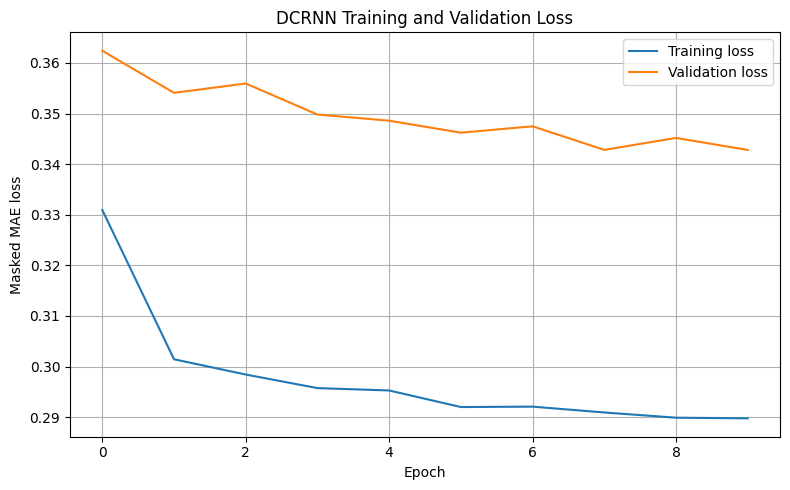

In [159]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training loss"
)

plt.plot(
    history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Masked MAE loss")
plt.title("DCRNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/loss_curve.png",
    dpi=200
)

plt.show()

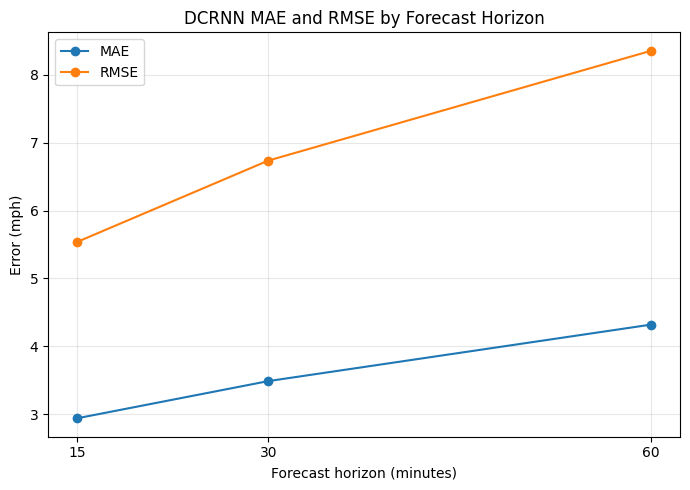

In [160]:
import os
import matplotlib.pyplot as plt

os.makedirs(RESULTS_DIR, exist_ok=True)

horizon_labels = [15, 30, 60]

mae = [
    dcrnn_metrics["15_min"]["MAE"],
    dcrnn_metrics["30_min"]["MAE"],
    dcrnn_metrics["60_min"]["MAE"]
]

rmse = [
    dcrnn_metrics["15_min"]["RMSE"],
    dcrnn_metrics["30_min"]["RMSE"],
    dcrnn_metrics["60_min"]["RMSE"]
]

plt.figure(figsize=(7, 5))

plt.plot(
    horizon_labels,
    mae,
    marker="o",
    label="MAE"
)

plt.plot(
    horizon_labels,
    rmse,
    marker="o",
    label="RMSE"
)

plt.xlabel("Forecast horizon (minutes)")
plt.ylabel("Error (mph)")
plt.title("DCRNN MAE and RMSE by Forecast Horizon")
plt.xticks(horizon_labels)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/error_metrics.png",
    dpi=200
)

plt.show()

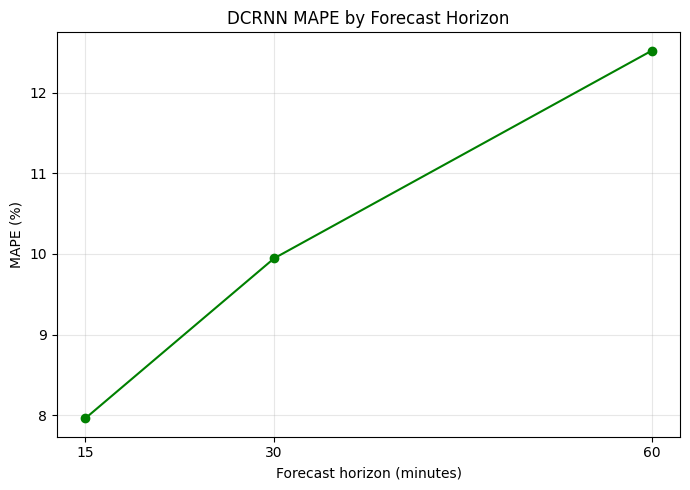

In [161]:
mape = [
    dcrnn_metrics["15_min"]["MAPE"],
    dcrnn_metrics["30_min"]["MAPE"],
    dcrnn_metrics["60_min"]["MAPE"]
]

plt.figure(figsize=(7, 5))

plt.plot(
    horizon_labels,
    mape,
    marker="o",
    color="green"
)

plt.xlabel("Forecast horizon (minutes)")
plt.ylabel("MAPE (%)")
plt.title("DCRNN MAPE by Forecast Horizon")
plt.xticks(horizon_labels)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/mape.png",
    dpi=200
)

plt.show()

In [162]:
import os
import shutil

DRIVE_RESULTS_DIR = (
    f"/content/drive/MyDrive/"
    f"CMPE258_TrafficForecastingUsing_GraphNN/"
    f"results/dcrnn_{GRAPH_NAME}_seed{SEED}"
)

os.makedirs(DRIVE_RESULTS_DIR, exist_ok=True)

for filename in [
    "metrics.json",
    "best_model.pt",
    "loss_curve.png",
    "error_metrics.png",
    "mape.png"
]:
    source = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(source):
        shutil.copy2(source, DRIVE_RESULTS_DIR)
        print("Copied:", filename)
    else:
        print("File not found:", source)

print("Saved results to:", DRIVE_RESULTS_DIR)

Copied: metrics.json
Copied: best_model.pt
Copied: loss_curve.png
Copied: error_metrics.png
Copied: mape.png
Saved results to: /content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/results/dcrnn_correlation_seed2024


In [163]:
import json
import os
import pandas as pd

drive_results_root = (
    "/content/drive/MyDrive/"
    "CMPE258_TrafficForecastingUsing_GraphNN/results"
)

rows = []

for seed in [42, 123, 2024]:
    metrics_path = (
        f"{drive_results_root}/"
        f"dcrnn_correlation_seed{seed}/metrics.json"
    )

    with open(metrics_path) as f:
        metrics = json.load(f)

    for horizon, values in metrics.items():
        rows.append({
            "graph": "correlation",
            "seed": seed,
            "horizon": horizon,
            "MAE": values["MAE"],
            "RMSE": values["RMSE"],
            "MAPE": values["MAPE"]
        })

correlation_summary = pd.DataFrame(rows)

print("Correlation-graph results for all seeds:")
display(correlation_summary)

Correlation-graph results for all seeds:


,graph,seed,horizon,MAE,RMSE,MAPE
0,correlation,42,15_min,2.938679,5.581029,7.908040
1,correlation,42,30_min,3.493303,6.834027,9.955481
2,correlation,42,60_min,4.356489,8.526371,13.068883
3,correlation,123,15_min,2.929414,5.555047,7.777642
4,correlation,123,30_min,3.474288,6.743168,9.842937
5,correlation,123,60_min,4.284294,8.329328,12.810431
6,correlation,2024,15_min,2.942174,5.536340,7.961770
7,correlation,2024,30_min,3.490207,6.735265,9.945599
8,correlation,2024,60_min,4.321895,8.351794,12.519485
